<a href="https://colab.research.google.com/github/vidaurre/glhmm/blob/main/docs/notebooks/HMM_state_selection_stochastic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HMM State Selection: Stochastic Training
#### with the [glhmm toolbox](https://github.com/vidaurre/glhmm)

Stochastic training is meant for datasets that are too big to load into memory at once. Instead of using all subjects in every training cycle, the model is updated with a small batch of subjects at a time, read from disk.

In this notebook we:
1. save the data as one file per subject,
2. train the HMM stochastically for a range of K,
3. check that the training converged by looking at the free energy,
4. choose K.

Choosing K works the same way as with standard training, so we keep that part short (see [HMM_state_selection_standard](HMM_state_selection_standard.ipynb) for more). If your data fit in memory, use that notebook instead, since standard training is simpler.

We use the same simulated dataset as in the standard notebook (100 subjects, 4800 timepoints, 50 features), made by **Christine Ahrends**. It would fit in memory, but it keeps things quick, and you can compare the results with the standard version. The aim is to show how the method works, not to find the "right" K for this dataset. The numbers in the text come from our own run, so yours can differ a bit.

Authors: Nick Yao Larsen <nylarsen@cfin.au.dk>

### Import libraries

In [39]:
# Install glhmm when using Google Colab
try:
    import google.colab
    IN_COLAB = True
    !pip install -q git+https://github.com/vidaurre/glhmm
except ImportError:
    IN_COLAB = False

import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from glhmm import glhmm, preproc, utils, graphics

### Download demo data

This downloads the demo data to `data/` if it isn't there already. You can skip it if you use your own data.

In [40]:
utils.osf_download_data('https://osf.io/8qcyj/', folder='Simulation_data_numpy')

Files already present in data/.


### Step 1. One file per subject

Stochastic training loads a few subjects from disk in every cycle, so the data need to be saved as one file per subject. Files that already exist are skipped.

If you use your own data, set `PATH_DATA` and `FILE_NAME` to an array of shape `(n_timepoints, n_subjects, n_features)`. If you already have one file per subject, you can go straight to Step 2.

In [41]:
PATH_DATA   = Path('data')
FILE_NAME   = 'data_sim.npy'
SUBJECT_DIR = Path('data_subject_files')

Y = np.load(PATH_DATA / FILE_NAME)
idx_data = np.load(PATH_DATA / 'idx_data.npy')     # start/end of each subject, used at the end
n_timepoints, n_subjects, n_features = Y.shape
print(f'Data: {n_subjects} subjects, {n_timepoints} timepoints, {n_features} features')

SUBJECT_DIR.mkdir(parents=True, exist_ok=True)
for i in range(n_subjects):
    file_path = SUBJECT_DIR / f'subject_{i:04d}.npy'
    if not file_path.exists():
        np.save(file_path, Y[:, i, :])

subject_files = sorted(SUBJECT_DIR.glob('subject_*.npy'), key=lambda p: int(p.stem.split('_')[-1]))
print(f'{len(subject_files)} subject files in {SUBJECT_DIR}')
del Y

Data: 100 subjects, 4800 timepoints, 50 features
100 subject files in data_subject_files


### Step 2. Preprocess

This is the same as in the standard notebook (each subject is z-scored), except that we pass the list of files. With `combine_outputs=False` we get one preprocessed file per subject back.

In [42]:
files_preproc, log_preproc = preproc.preprocess_data(
    files=subject_files,
    standardise=True,
    combine_outputs=False,        # one file per subject, needed for stochastic training
    output_dir=Path('data_subject_files_preprocessed'),
)
print(f'{len(files_preproc)} preprocessed files')

100 preprocessed files


### Step 3. Settings

In every cycle, stochastic training picks `Nbatch` subject files, estimates the model from that batch, and moves the current model a step towards it. The step gets smaller over the cycles, so the first batches change the model a lot and the later ones only adjust it. Because each update only sees a few subjects, the training is noisier than standard training, and runs from different random starts end up in different solutions more often.

So `cyc` isn't comparable to standard training, where every cycle uses all subjects. What matters is how often each subject is used over the whole training: about `cyc` x `Nbatch` / N times. Here that's 250 x 25 / 100 = 62.5 times. With 1,000 subjects and the same settings it would only be about 6 times, so the model would barely see each subject, and you'd need to increase `cyc` (or `Nbatch`). glhmm prints this number in its warning when the training hasn't converged.

| Option | Here | What it does |
|---|---|---|
| `Nbatch` | 25 | Number of subject files per cycle. A larger batch makes the training less noisy, but uses more memory |
| `cyc` | 250 | Number of training cycles |
| `forget_rate` | 0.75 | How quickly the step size shrinks. It should be between 0.5 and 1, otherwise the training isn't guaranteed to converge |
| `base_weights` | 0.25 | How much it favours subjects that haven't been used much, so all subjects are used about equally often |

Use at least 10 files per batch (the glhmm default), and more if memory allows. What matters is the number of files in a batch, not what fraction of the dataset it is. We use 25, since the demo files are small. With `Nbatch = 10` the training was about twice as fast, but the free energy curves were clearly bumpier.

Apart from `Nbatch`, these are the glhmm defaults. `deactivate_states=False` stops glhmm from switching off states that are hardly used during training, so every run keeps all K states and the K values can be compared. In our runs, no state was switched off. `COVTYPE` and `MODEL_MEAN` are the same as in the standard notebook (`'full'` and `'no'`). See Step 3 there for when to change them.

In [43]:
COVTYPE     = 'full'
MODEL_MEAN  = 'no'
state_range = range(3, 9)     # K values to try
n_repeats   = 5               # runs per K, from different random starts
SAVE_DIR    = Path.cwd() / 'results_stochastic'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

options = {
    'stochastic':        True,
    'Nbatch':            25,
    'cyc':               250,
    'forget_rate':       0.75,
    'base_weights':      0.25,
    'deactivate_states': False,
    'verbose':           False,
}

n_files = len(files_preproc)
print(f"Each subject is used about {options['cyc'] * options['Nbatch'] / n_files:.1f} times "
      f"({options['cyc']} x {options['Nbatch']} / {n_files})")

Each subject is used about 62.5 times (250 x 25 / 100)


### Step 4. Train

For each K and each run, we set the seed, train the model, decode the state time courses (stochastic training doesn't return them) and save everything to `hmm_K{K}_rep{run}.pkl`. Runs that are already saved are skipped, so you can stop the loop and continue later.

On our computer, one run took about 8 minutes for K=3 and 13 minutes for K=8, a bit over 5 hours in total. For a quicker first look, use `state_range = range(3, 7)` and `n_repeats = 3` (just under 2 hours). For 10 of the 30 runs, glhmm warned that the free energy was still going down at the end. We get back to that in Step 5.

In [16]:
for K in state_range:
    for rep in range(1, n_repeats + 1):
        model_path = SAVE_DIR / f'hmm_K{K}_rep{rep}.pkl'
        if model_path.exists():
            print(f'K={K} run {rep}: already trained')
            continue

        np.random.seed(rep - 1)
        hmm = glhmm.glhmm(K=K, covtype=COVTYPE, model_mean=MODEL_MEAN, model_beta='no',
                          preproclogY=log_preproc)
        options_run = dict(options)          # glhmm adds its defaults to this copy
        _, _, FE = hmm.train(files=files_preproc, options=options_run)
        Gamma, _, _ = hmm.decode(X=None, Y=None, files=files_preproc)

        with open(model_path, 'wb') as f:
            pickle.dump({'hmm': hmm, 'Gamma': Gamma, 'FE': FE, 'options': options_run}, f)
        print(f'K={K} run {rep}: {len(FE)} cycles', flush=True)
        del hmm, Gamma

K=3 run 1: 250 cycles
K=3 run 2: 250 cycles
K=3 run 3: 250 cycles
K=3 run 4: 250 cycles
K=3 run 5: 250 cycles
K=4 run 1: 250 cycles
K=4 run 2: 250 cycles


C:\Users\au323479\Github\glhmm\glhmm\glhmm.py:1288: UserWarning: The free energy was still decreasing at the end of training (cyc = 250), so the model has probably not converged. Each file was used about 62.5 times on average (cyc x Nbatch / N = 250 x 25 / 100). Increase cyc, or Nbatch if memory allows, and plot the free energy (third output of train(), e.g. with graphics.plot_free_energy) to check.
  warnings.warn("The free energy was still decreasing at the end of training (cyc = " + \


K=4 run 3: 250 cycles
K=4 run 4: 250 cycles
K=4 run 5: 250 cycles
K=5 run 1: 250 cycles


C:\Users\au323479\Github\glhmm\glhmm\glhmm.py:1288: UserWarning: The free energy was still decreasing at the end of training (cyc = 250), so the model has probably not converged. Each file was used about 62.5 times on average (cyc x Nbatch / N = 250 x 25 / 100). Increase cyc, or Nbatch if memory allows, and plot the free energy (third output of train(), e.g. with graphics.plot_free_energy) to check.
  warnings.warn("The free energy was still decreasing at the end of training (cyc = " + \


K=5 run 2: 250 cycles


C:\Users\au323479\Github\glhmm\glhmm\glhmm.py:1288: UserWarning: The free energy was still decreasing at the end of training (cyc = 250), so the model has probably not converged. Each file was used about 62.5 times on average (cyc x Nbatch / N = 250 x 25 / 100). Increase cyc, or Nbatch if memory allows, and plot the free energy (third output of train(), e.g. with graphics.plot_free_energy) to check.
  warnings.warn("The free energy was still decreasing at the end of training (cyc = " + \


... (11 outputs left out)

C:\Users\au323479\Github\glhmm\glhmm\glhmm.py:1288: UserWarning: The free energy was still decreasing at the end of training (cyc = 250), so the model has probably not converged. Each file was used about 62.5 times on average (cyc x Nbatch / N = 250 x 25 / 100). Increase cyc, or Nbatch if memory allows, and plot the free energy (third output of train(), e.g. with graphics.plot_free_energy) to check.
  warnings.warn("The free energy was still decreasing at the end of training (cyc = " + \


K=8 run 3: 250 cycles
K=8 run 4: 250 cycles


C:\Users\au323479\Github\glhmm\glhmm\glhmm.py:1288: UserWarning: The free energy was still decreasing at the end of training (cyc = 250), so the model has probably not converged. Each file was used about 62.5 times on average (cyc x Nbatch / N = 250 x 25 / 100). Increase cyc, or Nbatch if memory allows, and plot the free energy (third output of train(), e.g. with graphics.plot_free_energy) to check.
  warnings.warn("The free energy was still decreasing at the end of training (cyc = " + \


K=8 run 5: 250 cycles


### Step 5. Check convergence

Don't skip this step. Stochastic training rarely stops on its own, because the free energy goes up and down a bit from cycle to cycle. It usually runs all `cyc` cycles, so you need to check yourself whether it converged.

The plot shows the free energy of every run, one panel per K. We leave out the first 20 cycles, and all panels use the same y-scale.
- If a curve is flat at the end, the run has converged.
- If it's still going down, increase `cyc` and train again.
- If one run levels off clearly higher than the others, it got stuck in a worse solution.

The table under the plot shows how many runs per K were still going down at the end (the same check glhmm uses for the warning).

Loaded summary_results.pkl  (K = [3, 4, 5, 6, 7, 8])

    K | N reps | N sim scores |   Min final FE
--------------------------------------------
   3 |      5 |           10 |    32175972.52
   4 |      5 |           10 |    32114933.78
   5 |      5 |           10 |    31992763.76
   6 |      5 |           10 |    31952904.91
   7 |      5 |           10 |    31929164.94
   8 |      5 |           10 |    31828738.42


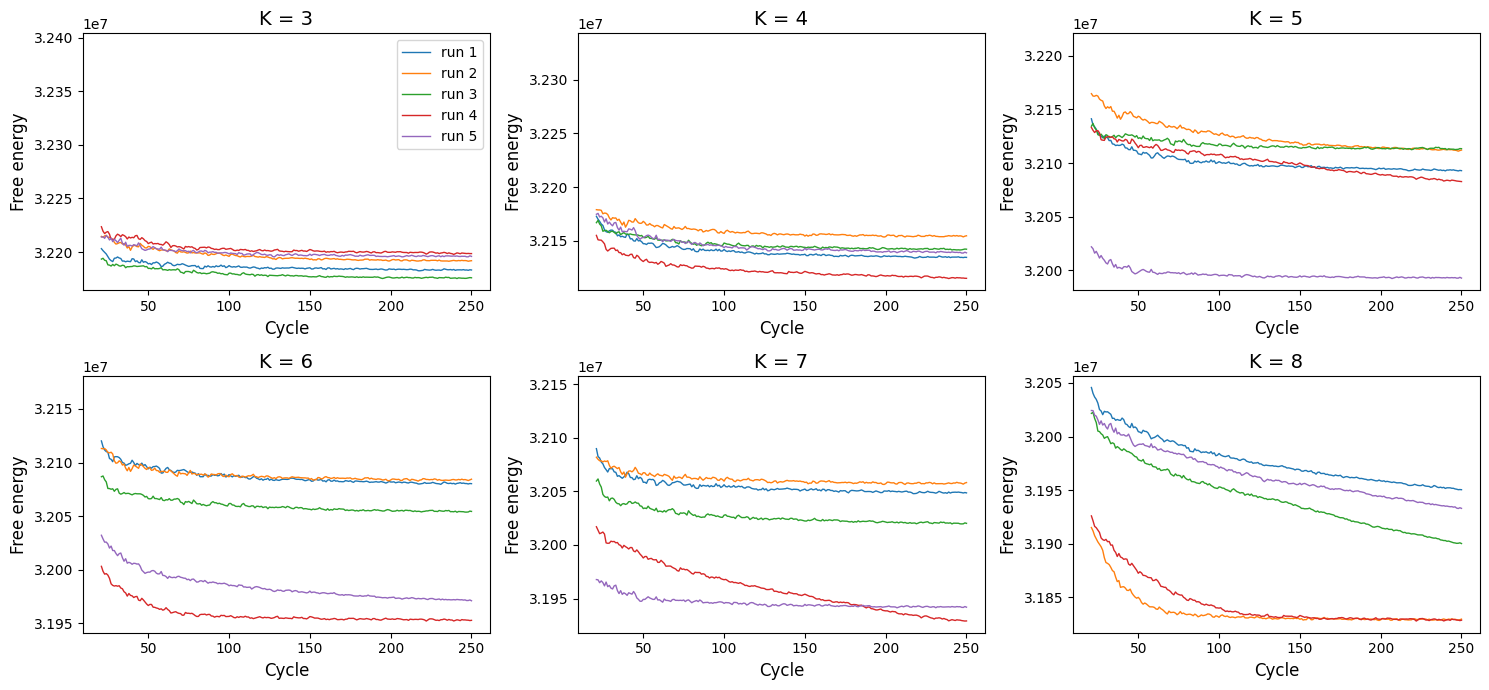

   K | runs | still decreasing at the end
   3 |    5 | 0
   4 |    5 | 1
   5 |    5 | 3
   6 |    5 | 1
   7 |    5 | 2
   8 |    5 | 3


In [44]:
# Load the free energy of every run, and the Gamma similarity between runs (used in Step 6).
# This also saves summary_results.pkl. If you train more runs later, delete that file first.
results, ks = utils.load_stability_results(SAVE_DIR)

n_still_decreasing = graphics.plot_free_energy(results, skip=20, save_path=SAVE_DIR / 'free_energy_curves.png')

The free energy tells you how good a solution is, but not which one it is. So we also plot the Gamma similarity between every pair of runs. A run that found something different from the others shows up as a row or column with low values.

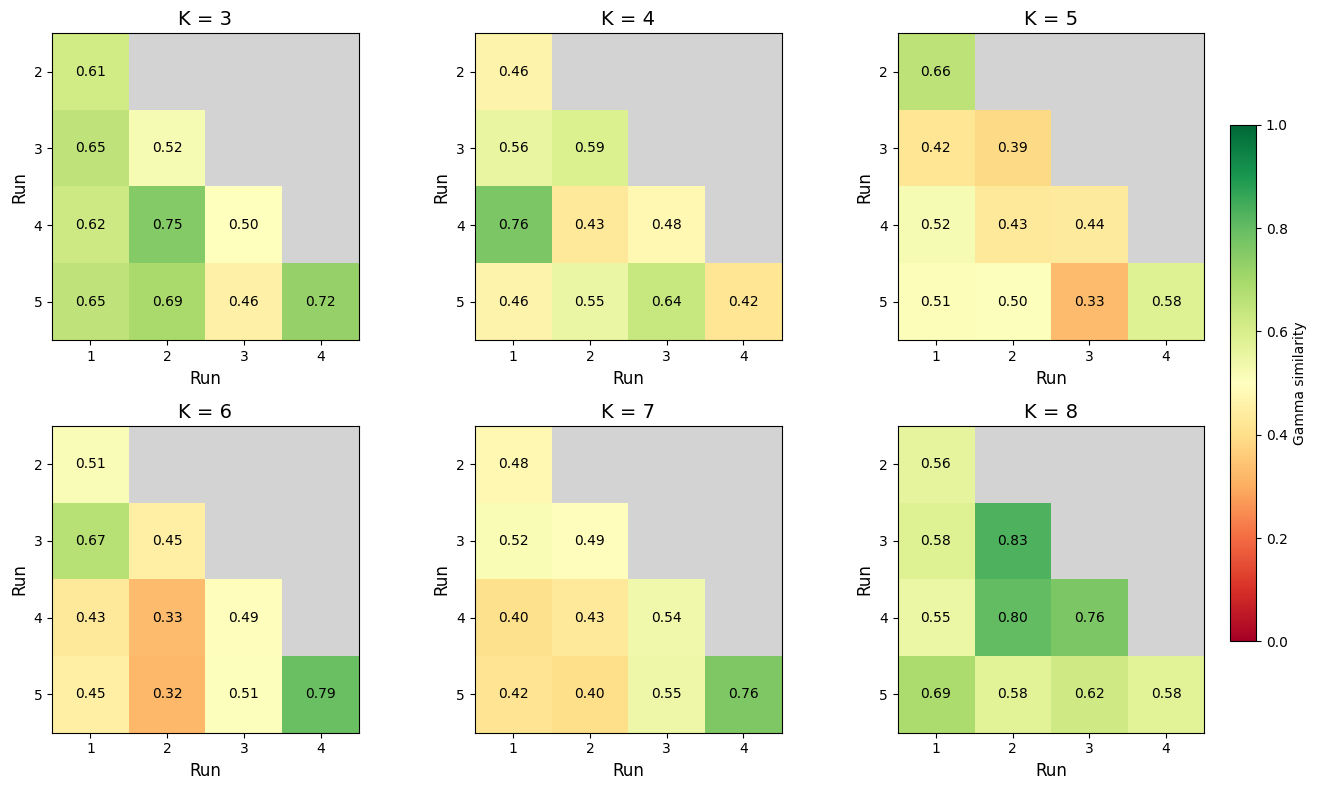

In [46]:
graphics.plot_similarity_matrix(results, cmap='RdYlGn', save_path=SAVE_DIR / 'similarity_matrix.png')

In our run, the runs end up at clearly different levels for K=5 to 8. For K=6, for example, runs 4 and 5 ended clearly below runs 1 to 3, and in the similarity matrix these two agree with each other (0.79) but not with the others (0.32 to 0.51). K=7 looks the same, with runs 4 and 5 agreeing at 0.76. So depending on the random start, the training ended up in different solutions. This happens more often than with standard training, and it's what lowers the stability in Step 6.

The table under the free energy plot says that 10 of the 30 runs were still going down at the end. For most of them it's only a slight slope in the plot. The clearest case is K=8, where runs 1, 3 and 5 are still going down and are well above runs 2 and 4. Run 3 already agrees well with runs 2 and 4 in the similarity matrix (0.83 and 0.76), so it seems to be heading for the same solution but hasn't got there yet. Runs 1 and 5 don't (0.55 to 0.69 with the other runs), so they found something else. More cycles would probably help run 3, but for runs 1 and 5 the random start is the problem, which is why we train several runs per K. With your own data, if a curve is still clearly going down, increase `cyc` and train again.

### Step 6. Choose K

We use the same plot as in the standard notebook, `graphics.plot_model_selection()`: stability on the left, fit in the middle, and the best run of each K on the right. With stochastic training the similarity is usually lower than with standard training, so compare the K values with each other rather than with the 0.8 line. The elbow line is only a hint, so also check how much the free energy still goes down after it.

The fit panel and the `Min FE/T` column work as in the standard notebook, with one difference. Since the free energy goes up and down a bit, we set `n_last=10`, so the free energy at the end of a run is the mean of its last 10 cycles (not the lowest value along the way, since glhmm keeps the model from the last cycle). For each K, the run with the lowest end value is the best run, and its end value divided by the total number of timepoints (480,000 here) is what's shown. In the table under the figure, the last column (`Converged?`) then shows how many runs of each K were still going down at the end, e.g. `CHECK 3/5` means 3 of the 5 runs.

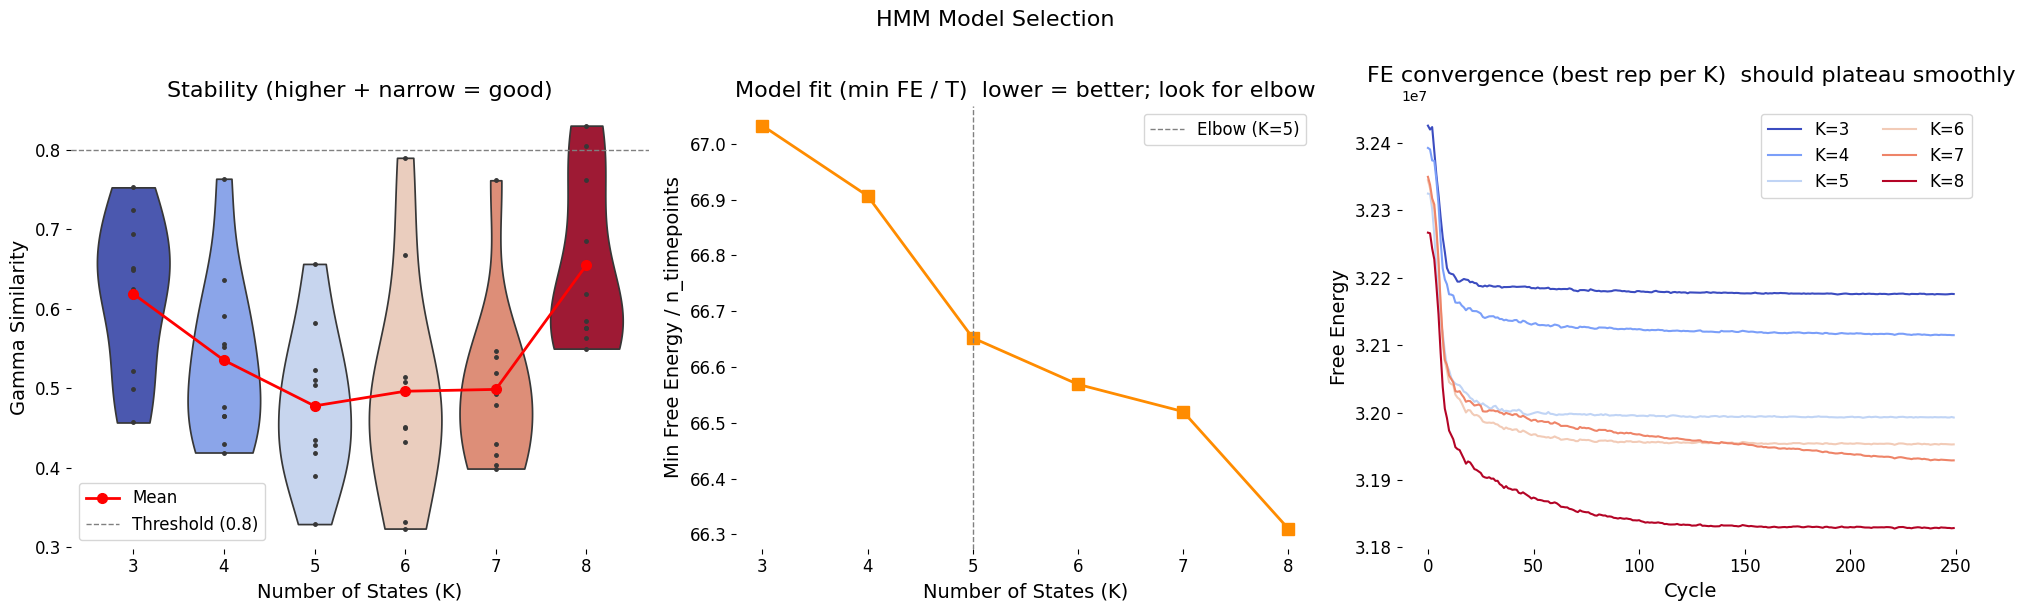

    K |  Mean Sim |  Std Sim |   Min FE/T | Converged?
----------------------------------------------------
   3 |    0.6186 |   0.0931 |      67.03 |        yes
   4 |    0.5351 |   0.1019 |      66.91 |  CHECK 1/5
   5 |    0.4776 |   0.0918 |      66.65 |  CHECK 3/5
   6 |    0.4961 |   0.1345 |      66.57 |  CHECK 1/5
   7 |    0.4984 |   0.1022 |      66.52 |  CHECK 2/5
   8 |    0.6548 |   0.1020 |      66.31 |  CHECK 3/5


In [47]:
n_total_timepoints = n_timepoints * n_subjects
avg_similarity, min_fe = graphics.plot_model_selection(results, n_total_timepoints, n_last=10,
                                                       save_path=SAVE_DIR / 'model_selection.png')

In our run, the stability is low for every K (0.48 to 0.65 in the `Mean Sim` column), clearly lower than in the standard notebook (0.73 to 0.87). That's expected with stochastic training. The elbow line is at K=5, but the free energy keeps going down after that (from 66.65 at K=5 to 66.31 at K=8 in the `Min FE/T` column). K=8 is both the most stable (0.65) and has the lowest free energy, so we go with K=8, the same as in the standard notebook.

K=8 is the highest K we tried. That's fine for a demo, but with your own data, if the K you'd pick is at the edge of the range, train some higher K values too before you decide.

### Step 7. Look at the chosen model

To keep it simple, we take the run with the lowest end free energy, and plot its state covariances and how much time each subject spends in each state (fractional occupancy). If a state only shows up in a few subjects, it may capture differences between subjects rather than a state they all share.

K = 8, run 4 (hmm_K8_rep4.pkl)


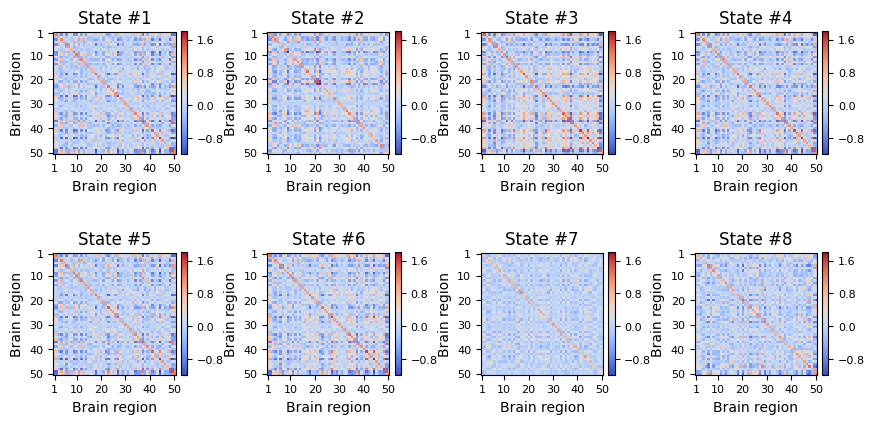

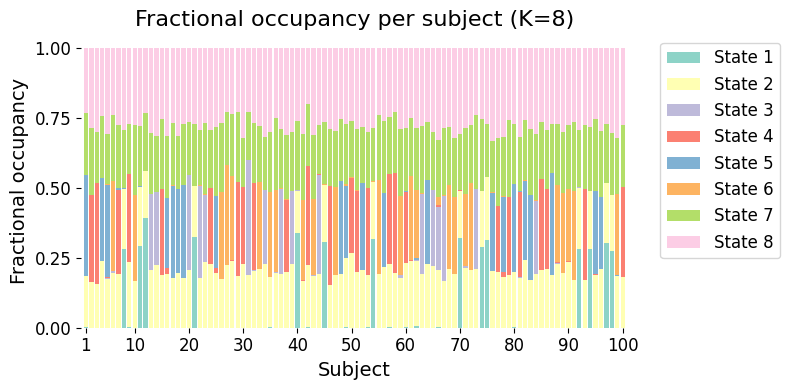

In [52]:
CHOSEN_K = 8   # set after looking at the plots above

# the run with the lowest end free energy (mean of the last 10 cycles)
end_fe = [np.mean(fe[-10:]) for fe in results[CHOSEN_K]['FE']]
best_rep = int(np.argmin(end_fe)) + 1
best_path = SAVE_DIR / f'hmm_K{CHOSEN_K}_rep{best_rep}.pkl'
with open(best_path, 'rb') as f:
    best = pickle.load(f)
print(f'K = {CHOSEN_K}, run {best_rep} ({best_path.name})')

graphics.plot_state_covariances(best['hmm'].get_covariance_matrices(), cmap='coolwarm',
                                same_scale=True, num_cols=4)
plt.show()

FO = utils.get_FO(best['Gamma'], idx_data)        # fractional occupancy, subjects x states
graphics.plot_FO(FO, title=f'Fractional occupancy per subject (K={CHOSEN_K})')
plt.show()

### Reporting
Once you've chosen K, the model can be used for further analysis, e.g. statistical testing (see our [Nature Protocols paper](https://www.nature.com/articles/s41596-025-01300-2) and the [code](https://github.com/Nick7900/glhmm_protocols)) or [prediction](https://github.com/vidaurre/glhmm/blob/main/docs/notebooks/Prediction_tutorial.ipynb).